Analyse image

In [2]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')


I0000 00:00:1793976667.226254   60905 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793976667.226531   60905 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793976667.250447   60905 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793976667.841107   60905 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

<function matplotlib.pyplot.show(close=None, block=None)>

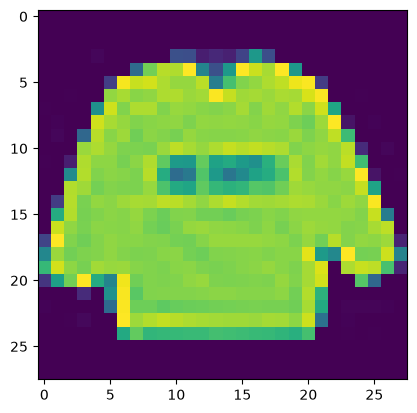

In [3]:
X = np.array(observations_entrainement.iloc[:, 1:])
premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE, LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show

In [4]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [5]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE,1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255


In [6]:
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:,0]))
X_test = X_test.reshape(X_test.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

In [7]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

dimensionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
reseauNeurone1Convolution = Sequential()

reseauNeurone1Convolution.add(Input(shape=dimensionImage))

reseauNeurone1Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))

reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2,2)))
reseauNeurone1Convolution.add(Dropout(0.2))
reseauNeurone1Convolution.add(Flatten())

reseauNeurone1Convolution.add(Dense(128, activation='relu'))
reseauNeurone1Convolution.add(Dense(10,activation='softmax'))

In [8]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy,optimizer=tf.keras.optimizers.Adam(), metrics=['accuracy'])

In [9]:
historique_apprentissage = reseauNeurone1Convolution.fit(X_apprentissage, y_apprentissage, batch_size=256, epochs=10, 
                                                         verbose=1, validation_data=(X_validation, y_validation))


Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8066 - loss: 0.5461 - val_accuracy: 0.8633 - val_loss: 0.3912
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8737 - loss: 0.3553 - val_accuracy: 0.8831 - val_loss: 0.3374
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8890 - loss: 0.3140 - val_accuracy: 0.8900 - val_loss: 0.3102
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8982 - loss: 0.2869 - val_accuracy: 0.8951 - val_loss: 0.2947
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9052 - loss: 0.2671 - val_accuracy: 0.8989 - val_loss: 0.2834
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9111 - loss: 0.2496 - val_accuracy: 0.8925 - val_loss: 0.2946
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9171 - loss: 0.2328 - val_accuracy: 0.9034 - val_loss: 0.2658
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9196 - loss: 0.2219 - val_accu

In [10]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('ErreurL', evaluation[0])
print('Precision:', evaluation[1])

ErreurL 0.2367120087146759
Precision: 0.9150000214576721


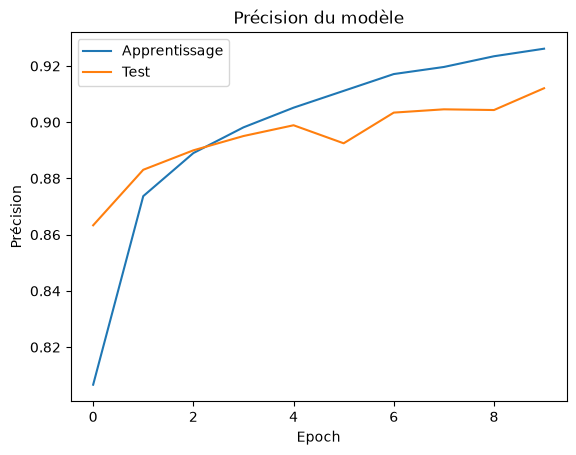

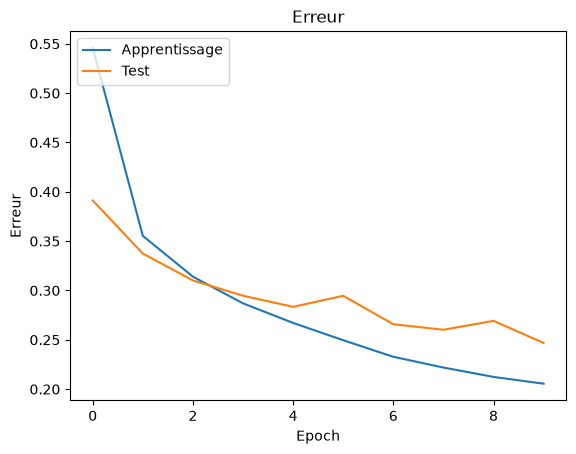

In [11]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08
)

In [13]:
nouvelles_images_apprentissage = generateur_images.flow(X_apprentissage, y_apprentissage, batch_size=256)

nouvelles_images_validation = generateur_images.flow(X_validation,y_validation, batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1
)

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Precision :', evaluation[1])

Epoch 1/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 37s 200ms/step - accuracy: 0.7461 - loss: 0.6623

I0000 00:00:1793976698.932740   60905 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.8281 - loss: 0.4601 - val_accuracy: 0.8408 - val_loss: 0.4222
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8242 - loss: 0.4515

/home/waheed/Documents/DEPOTS/420-5G4-ML-WS-momo/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8242 - loss: 0.4515 - val_accuracy: 0.8462 - val_loss: 0.4130
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.8463 - loss: 0.4100 - val_accuracy: 0.8499 - val_loss: 0.4042
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8359 - loss: 0.4525 - val_accuracy: 0.8509 - val_loss: 0.3990
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8575 - loss: 0.3854 - val_accuracy: 0.8631 - val_loss: 0.3727
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8711 - loss: 0.3241 - val_accuracy: 0.8607 - val_loss: 0.3690
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.8622 - loss: 0.3704 - val_accuracy: 0.8665 - val_loss: 0.3593
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8594 - loss: 0.3827 - val_accuracy: 0.8670 - val_loss: 0.3577
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8660 - loss: 0.3605 - val_accuracy: 0.8596 - 

In [14]:
model_json = reseauNeurone1Convolution.to_json()
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)

reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modele sauvegarde !")

Modele sauvegarde !


In [15]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimensionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

/home/waheed/Documents/DEPOTS/420-5G4-ML-WS-momo/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy,optimizer=tf.keras.optimizers.Adam(), metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(X_apprentissage, y_apprentissage, batch_size=256, epochs=10, verbose=1,
                                                          validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.7408 - loss: 0.7477 - val_accuracy: 0.1248 - val_loss: 3.7510
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.8425 - loss: 0.4397 - val_accuracy: 0.4912 - val_loss: 1.8603
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.8706 - loss: 0.3619 - val_accuracy: 0.7908 - val_loss: 0.6020
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 52ms/step - accuracy: 0.8848 - loss: 0.3236 - val_accuracy: 0.8955 - val_loss: 0.3005
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.8950 - loss: 0.3000 - val_accuracy: 0.9026 - val_loss: 0.2770
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.8993 - loss: 0.2827 - val_accuracy: 0.9107 - val_loss: 0.2533
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.9045 - loss: 0.2673 - val_accuracy: 0.9068 - val_loss: 0.2549
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.9105 - loss: 0.2532 - 

In [17]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Precision:', evaluation[1])

Erreur: 0.20406483113765717
Precision: 0.9262999892234802


In [18]:
historique_apprentissage = reseauNeurones4Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1
)

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Precision :', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.8576 - loss: 0.3973 - val_accuracy: 0.8764 - val_loss: 0.3305
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 18s 97ms/step - accuracy: 0.8359 - loss: 0.3868

/home/waheed/Documents/DEPOTS/420-5G4-ML-WS-momo/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8359 - loss: 0.3868 - val_accuracy: 0.8801 - val_loss: 0.3312
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.8676 - loss: 0.3634 - val_accuracy: 0.8907 - val_loss: 0.3047
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8789 - loss: 0.3686 - val_accuracy: 0.8896 - val_loss: 0.3012
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.8781 - loss: 0.3379 - val_accuracy: 0.8807 - val_loss: 0.3323
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8711 - loss: 0.3379 - val_accuracy: 0.8754 - val_loss: 0.3451
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.8817 - loss: 0.3242 - val_accuracy: 0.8960 - val_loss: 0.2819
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8750 - loss: 0.3374 - val_accuracy: 0.8996 - val_loss: 0.2806
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.8860 - loss: 0.3179 - val_accuracy: 0.888

In [19]:
model_json = reseauNeurones4Convolution.to_json()
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)

reseauNeurones4Convolution.save_weights("modele/modele.weights.h5")
print("Modele sauvegarde !")

Modele sauvegarde !
